# Reduced KNN for hardware: replace training flows with centroids (N = 5, raw features)

The full KNN from `training_binary_knn_n5_k1.ipynb` stores **every training flow (700,000)** and, for each new flow,
computes the distance to all of them. That is far too many operations per inference for hardware.

**Idea.** Summarize each class by a small number of representative points: run k-means separately on the attack
flows and on the benign flows, keep **C centroids per class** (2·C points in total), and run KNN on the centroids
instead of the training flows. One inference then needs 2·C distance computations instead of 700,000.

**Question.** How small can the model get while keeping the full model's performance?

| What is compared | Values |
|---|---|
| Full model | KNN on all training flows, every K (from the saved full-model bundle) |
| Reduced models | KNN on C centroids per class, every C in `C_VALUES` × every K in `K_VALUES` (K ≤ 2·C) |
| Metrics | F1, precision, recall, false-positive rate (FPR), false-negative rate (FNR) on the same test split |
| Cost | stored points, distance computations, arithmetic operations, comparisons per inference |

**Steps:** 1 setup → 2 load the full model bundle → 3 cost of one inference → 4 full-model baseline →
5 build centroids → 6 visualize centroids → 7 evaluate every (C, K) → 8 compare → 9 choose the reduced model →
10 save → 11 check the saved model reloads.

Features, units and flow definition are unchanged: `total_bytes`, `packet_length_max`, `iat_max` from the first 5
packets, raw values (see Section 2 of `training_binary_knn_n5_k1.ipynb` for how they are extracted from live traffic).

## 1. Setup

In [3]:
import json
import platform
import time
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.neighbors import KNeighborsClassifier

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

PROJECT_DIR = Path("/home/ubuntu/DDoS_ML")
FULL_BUNDLE_DIR = PROJECT_DIR / "offline" / "models" / "knn_n5_raw" / "knn_n5_raw_k1"   # full model (input)
MODELS_DIR = PROJECT_DIR / "offline" / "models" / "knn_n5_raw_reduced"                  # reduced models (output)
RESULTS_DIR = PROJECT_DIR / "offline" / "results" / "knn_n5_raw_reduced"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

C_VALUES = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]   # centroids per class
K_VALUES = [1, 3, 5, 7, 9, 11, 15]                      # neighbors (odd: no ties); only K <= 2*C is valid

# "Same performance" = within these tolerances of the full model (Section 9).
MAX_F1_DROP = 0.001          # reduced F1  >= full F1  - 0.001
MAX_FPR_INCREASE = 0.001     # reduced FPR <= full FPR + 0.001

RANDOM_STATE = 42
CLASS_NAMES = {0: "benign", 1: "attack"}
CLASS_COLORS = {0: "tab:blue", 1: "tab:red"}

## 2. Load the full model bundle

The reduced models are built from the **same training flows** and tested on the **same test flows** as the full
model, so the comparison is fair. Both come from the bundle saved by `training_binary_knn_n5_k1.ipynb`.

In [4]:
full_meta = json.loads((FULL_BUNDLE_DIR / "metadata.json").read_text())
FEATURES = full_meta["features"]
N = full_meta["flow"]["N_packets"]

train_points = pd.read_csv(FULL_BUNDLE_DIR / "training_points.csv")
test_df = pd.read_csv(FULL_BUNDLE_DIR / "test_split.csv")
full_results = pd.read_csv(FULL_BUNDLE_DIR / "results_all_k.csv")

X_train, y_train = train_points[FEATURES].to_numpy(), train_points["label"].to_numpy()
X_test, y_test = test_df[FEATURES].to_numpy(), test_df["y"].to_numpy()

print(f"Features: {FEATURES}   N = {N}   full model K = {full_meta['k']}")
print(f"Training flows: {len(X_train):,}  (attack {y_train.sum():,}, benign {(y_train == 0).sum():,})")
print(f"Test flows:     {len(X_test):,}  (attack {y_test.sum():,}, benign {(y_test == 0).sum():,})")
assert set(K_VALUES) <= set(full_results["k"]), "full-model results are needed for every K"

Features: ['total_bytes', 'packet_length_max', 'iat_max']   N = 5   full model K = 1
Training flows: 700,000  (attack 350,000, benign 350,000)
Test flows:     300,000  (attack 150,000, benign 150,000)


## 3. Cost of one inference

A KNN stored as `M` points (each: 3 feature values + 1 label) classifies one flow by brute force:

```
for each stored point (x1, x2, x3, label):                 # M times
    d = (f1 - x1)^2 + (f2 - x2)^2 + (f3 - x3)^2            # 3 sub, 3 mul, 2 add  (no sqrt needed)
    if d is smaller than the K-th smallest so far:          # up to K comparisons to insert into a sorted list
        insert (d, label) into the list of the K smallest
attack_votes = number of labels equal to 1 in the list
predict attack if attack_votes > K / 2
```

Per inference: **M distance computations**, **8·M arithmetic operations**, and at most **M·K comparisons**
(exactly M for K = 1, a running minimum). Memory: **3·M stored values**. The full model has M = 700,000; a reduced
model has M = 2·C.

In [5]:
def inference_cost(m, k):
    return {"stored_points": m, "stored_values": 3 * m, "distance_computations": m,
            "arithmetic_ops": 8 * m, "comparisons": m * k}


pd.DataFrame([{"model": "full", "M": len(X_train)}] + [{"model": f"C={c}", "M": 2 * c} for c in C_VALUES]) \
  .assign(**{"distance computations per inference": lambda d: d.M,
             "arithmetic ops per inference": lambda d: 8 * d.M,
             "x fewer than full": lambda d: len(X_train) / d.M}).set_index("model")

,M,distance computations per inference,arithmetic ops per inference,x fewer than full
model,,,,
full,700000,700000,5600000,1.0
C=1,2,2,16,350000.0
C=2,4,4,32,175000.0
C=5,10,10,80,70000.0
C=10,20,20,160,35000.0
C=20,40,40,320,17500.0
C=50,100,100,800,7000.0
C=100,200,200,1600,3500.0
C=200,400,400,3200,1750.0


## 4. Full-model baseline

Test results of the full KNN for every K (computed in `training_binary_knn_n5_k1.ipynb` on this same test split).
The saved full model uses `K = full_meta["k"]`; it is the reference for "same performance".

In [6]:
METRICS = ["accuracy", "precision", "recall", "f1", "fpr", "fnr"]
full = full_results[["k"] + METRICS + ["tp", "fp", "tn", "fn"]].copy()
full = full.assign(model="full", C=np.nan, **inference_cost(len(X_train), full["k"]))
reference = full[full["k"] == full_meta["k"]].iloc[0]

with pd.option_context("display.float_format", "{:.5f}".format):
    display(full.set_index("k")[METRICS + ["distance_computations", "comparisons"]])
print(f"Reference (full model, K={int(reference.k)}): F1 = {reference.f1:.5f}   FPR = {reference.fpr:.5f}")

,accuracy,precision,recall,f1,fpr,fnr,distance_computations,comparisons
k,,,,,,,,
1,0.99989,0.99990,0.99989,0.99989,0.00010,0.00011,700000,700000
3,0.99987,0.99988,0.99987,0.99987,0.00012,0.00013,700000,2100000
5,0.99987,0.99987,0.99986,0.99987,0.00013,0.00014,700000,3500000
7,0.99987,0.99988,0.99986,0.99987,0.00012,0.00014,700000,4900000
9,0.99986,0.99988,0.99983,0.99986,0.00012,0.00017,700000,6300000
11,0.99984,0.99988,0.99980,0.99984,0.00012,0.00020,700000,7700000
15,0.99983,0.99988,0.99978,0.99983,0.00012,0.00022,700000,10500000


Reference (full model, K=1): F1 = 0.99989   FPR = 0.00010


## 5. Build the centroids

For each C, k-means is run **separately on each class** of the training flows, giving C attack centroids and
C benign centroids. Each centroid keeps its class label, so the reduced model is simply a KNN on 2·C labeled points.

* k-means runs on the **raw** features, i.e. with the same Euclidean distance the KNN uses, so the centroids are
  representative under the distance that will be used for classification.
* Only the training flows are used; the test flows stay unseen.
* `MiniBatchKMeans` is used because it is fast on 350,000 flows per class and gives nearly the same centroids as
  standard k-means.

In [7]:
centroid_sets = {}
centroid_dir = MODELS_DIR / "centroids"
centroid_dir.mkdir(exist_ok=True)

for c in C_VALUES:
    t0 = time.time()
    parts = []
    for label in (0, 1):
        km = MiniBatchKMeans(n_clusters=c, batch_size=10_000, n_init=3, random_state=RANDOM_STATE)
        km.fit(X_train[y_train == label])
        parts.append(pd.DataFrame(km.cluster_centers_, columns=FEATURES).assign(label=label))
    centroid_sets[c] = pd.concat(parts, ignore_index=True)
    centroid_sets[c].to_csv(centroid_dir / f"centroids_c{c}.csv", index=False)
    print(f"C={c:>5}: {len(centroid_sets[c]):>5} centroids  ({time.time() - t0:.1f}s)")
print(f"All centroid sets saved in {centroid_dir}")

C=    1:     2 centroids  (0.8s)
C=    2:     4 centroids  (0.9s)
C=    5:    10 centroids  (1.0s)
C=   10:    20 centroids  (1.0s)
C=   20:    40 centroids  (0.9s)
C=   50:   100 centroids  (1.0s)
C=  100:   200 centroids  (1.7s)
C=  200:   400 centroids  (2.5s)
C=  500:  1000 centroids  (4.5s)
C= 1000:  2000 centroids  (7.8s)
All centroid sets saved in /home/ubuntu/DDoS_ML/offline/models/knn_n5_raw_reduced/centroids


## 6. Visualize the centroids

Training flows (faint) with the centroids on top (large markers), for a small and a large C. Axes are
`log10(value)` (`iat_max = 0` is drawn at −7).

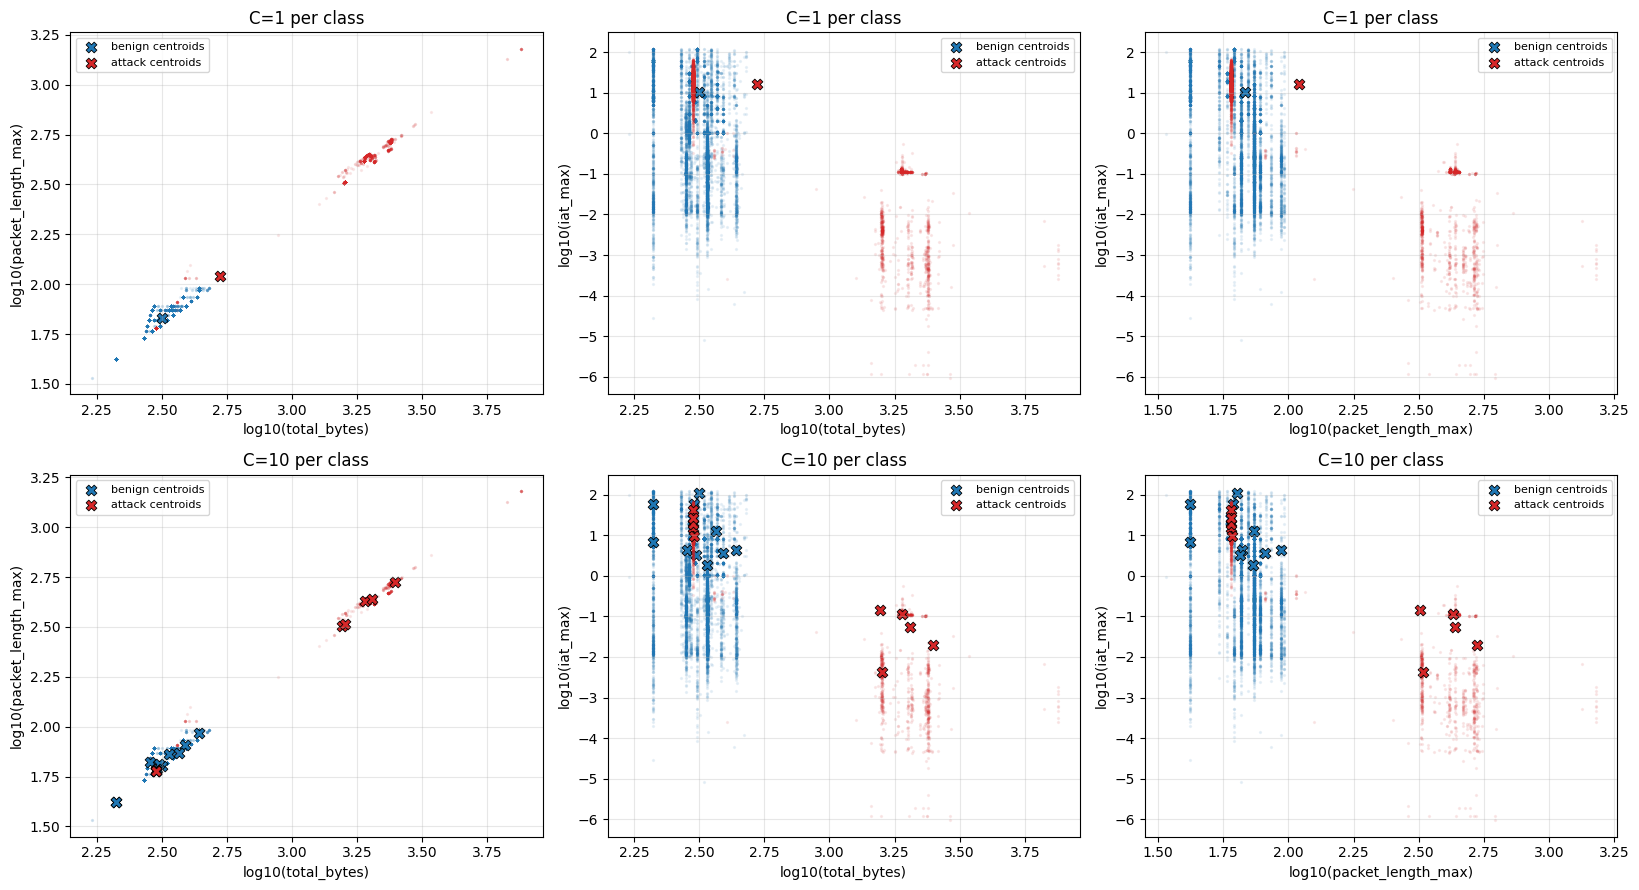

In [8]:
SHOW_C = [c for c in (1,10) if c in C_VALUES]
log = lambda v: np.log10(np.clip(v, 1e-7, None))
rng = np.random.default_rng(RANDOM_STATE)
bg = rng.choice(len(X_train), size=min(20_000, len(X_train)), replace=False)
pairs = list(combinations(range(len(FEATURES)), 2))

fig, axes = plt.subplots(len(SHOW_C), len(pairs), figsize=(5.5 * len(pairs), 4.5 * len(SHOW_C)), squeeze=False)
for row, c in enumerate(SHOW_C):
    cents = centroid_sets[c]
    for col, (i, j) in enumerate(pairs):
        ax = axes[row, col]
        for label, color in CLASS_COLORS.items():
            pts = X_train[bg][y_train[bg] == label]
            ax.scatter(log(pts[:, i]), log(pts[:, j]), s=2, alpha=0.08, color=color)
            cc = cents[cents.label == label]
            ax.scatter(log(cc[FEATURES[i]]), log(cc[FEATURES[j]]), s=60, marker="X", color=color,
                       edgecolor="black", linewidth=0.6, label=f"{CLASS_NAMES[label]} centroids")
        ax.set(xlabel=f"log10({FEATURES[i]})", ylabel=f"log10({FEATURES[j]})", title=f"C={c} per class")
        ax.grid(alpha=0.3)
        ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "centroids.png", dpi=150)
plt.show()

## 7. Evaluate every (C, K)

For each centroid set and each valid K (K ≤ 2·C), fit a KNN on the centroids and classify the test flows. The
heatmaps show every metric for every (C, K): rows are centroids per class, columns are K. Blank cells are invalid
combinations (K larger than the number of centroids). **Brighter is better** in every panel (the colors are reversed
for the false-positive and false-negative rates). Colors are limited to 0.95–1 for the scores and 0–5% for the error
rates so that differences between the good models are visible; every cell outside that range is drawn in the darkest
color, and the number in the cell is always exact.
A bright precision (1.0) or false-positive rate (0.0) next to a very low F1 means the model almost never
flags anything as an attack: read the heatmaps together, not one at a time.

Evaluated 57 reduced models; results saved to /home/ubuntu/DDoS_ML/offline/results/knn_n5_raw_reduced/results_full_vs_reduced.csv


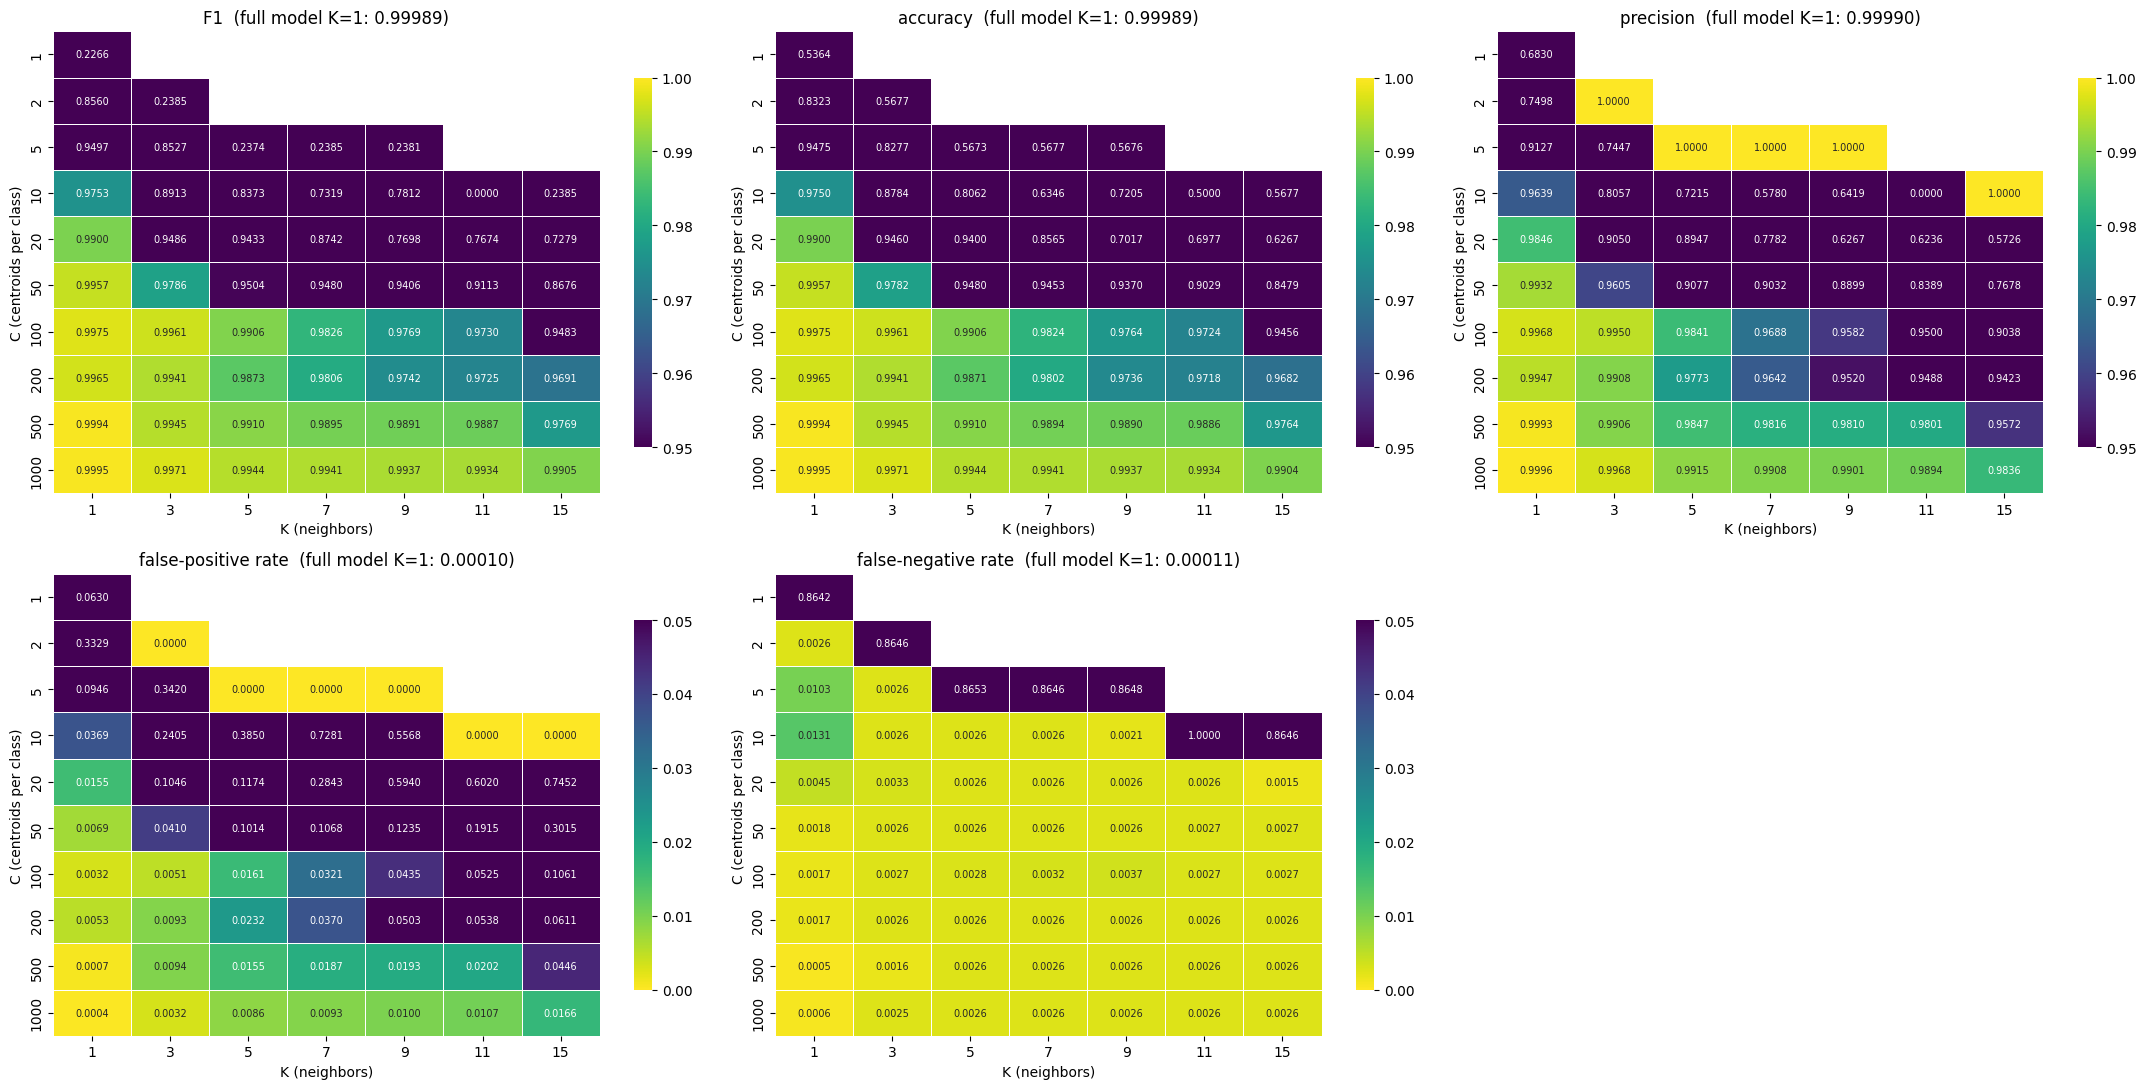

In [9]:
rows, reduced_models, reduced_preds = [], {}, {}
for c in C_VALUES:
    cents = centroid_sets[c]
    for k in [k for k in K_VALUES if k <= len(cents)]:
        model = KNeighborsClassifier(n_neighbors=k).fit(cents[FEATURES].to_numpy(), cents["label"].to_numpy())
        y_pred = model.predict(X_test)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
        reduced_models[(c, k)], reduced_preds[(c, k)] = model, y_pred
        rows.append({"model": "reduced", "C": c, "k": k,
                     "accuracy": accuracy_score(y_test, y_pred), "precision": precision_score(y_test, y_pred, zero_division=0),
                     "recall": recall_score(y_test, y_pred), "f1": f1_score(y_test, y_pred),
                     "fpr": fp / (fp + tn), "fnr": fn / (fn + tp), "tp": tp, "fp": fp, "tn": tn, "fn": fn,
                     **inference_cost(len(cents), k)})

reduced = pd.DataFrame(rows)
all_results = pd.concat([full, reduced], ignore_index=True)
all_results.to_csv(RESULTS_DIR / "results_full_vs_reduced.csv", index=False)
print(f"Evaluated {len(reduced)} reduced models; results saved to {RESULTS_DIR / 'results_full_vs_reduced.csv'}")

HEATMAPS = [("f1", "F1", "viridis", (0.95, 1.0)), ("accuracy", "accuracy", "viridis", (0.95, 1.0)),
            ("precision", "precision", "viridis", (0.95, 1.0)),
            ("fpr", "false-positive rate", "viridis_r", (0.0, 0.05)), ("fnr", "false-negative rate", "viridis_r", (0.0, 0.05))]
fig, axes = plt.subplots(2, 3, figsize=(22, 11))
for ax, (metric, title, cmap, (vmin, vmax)) in zip(axes.flat, HEATMAPS):
    grid = reduced.pivot(index="C", columns="k", values=metric)
    sns.heatmap(grid, annot=True, fmt=".4f", annot_kws={"size": 7}, cmap=cmap, vmin=vmin, vmax=vmax, ax=ax, linewidths=0.5,
                cbar_kws={"shrink": 0.8})
    ax.set(title=f"{title}  (full model K={int(reference.k)}: {reference[metric]:.5f})",
           xlabel="K (neighbors)", ylabel="C (centroids per class)")
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "reduced_metrics_heatmaps.png", dpi=150)
plt.show()

## 8. Compare full and reduced models

The plots show **error rates**, not scores, on **logarithmic axes**, because every good model is close to F1 = 1 and
the differences are invisible on a normal scale.

**How to read the axes**

* **x-axis, first three panels: C, the number of centroids per class.** The reduced model stores 2·C points.
  The scale is logarithmic: each labeled tick (1, 10, 100, 1000) is 10× the previous one.
* **x-axis, last panel: distance computations per inference**, i.e. how many stored points one flow is compared with
  (2·C for a reduced model, 700,000 for the full model). Further left = cheaper.
* **y-axis: an error rate in percent, lower is better.** Also logarithmic: going down one labeled tick means 10× fewer
  errors (10% → 1% → 0.1% → 0.01%).
  * `1 − F1`: an F1 of 0.999 is plotted at 0.1%, an F1 of 0.9999 at 0.01%.
  * `1 − accuracy`: the share of all test flows classified wrongly.
  * `false-positive rate`: the share of benign test flows wrongly flagged as attacks.
* **Black dashed line:** the full model (reference K). **Green line:** the tolerance limit. A point **below the green
  line** has the "same performance" as the full model.
* Points drawn at the very bottom of the FPR panel are models that never flag anything (FPR = 0); the other panels
  show they are useless.

The best trade-off is a point that is **below the green line and as far left as possible**.

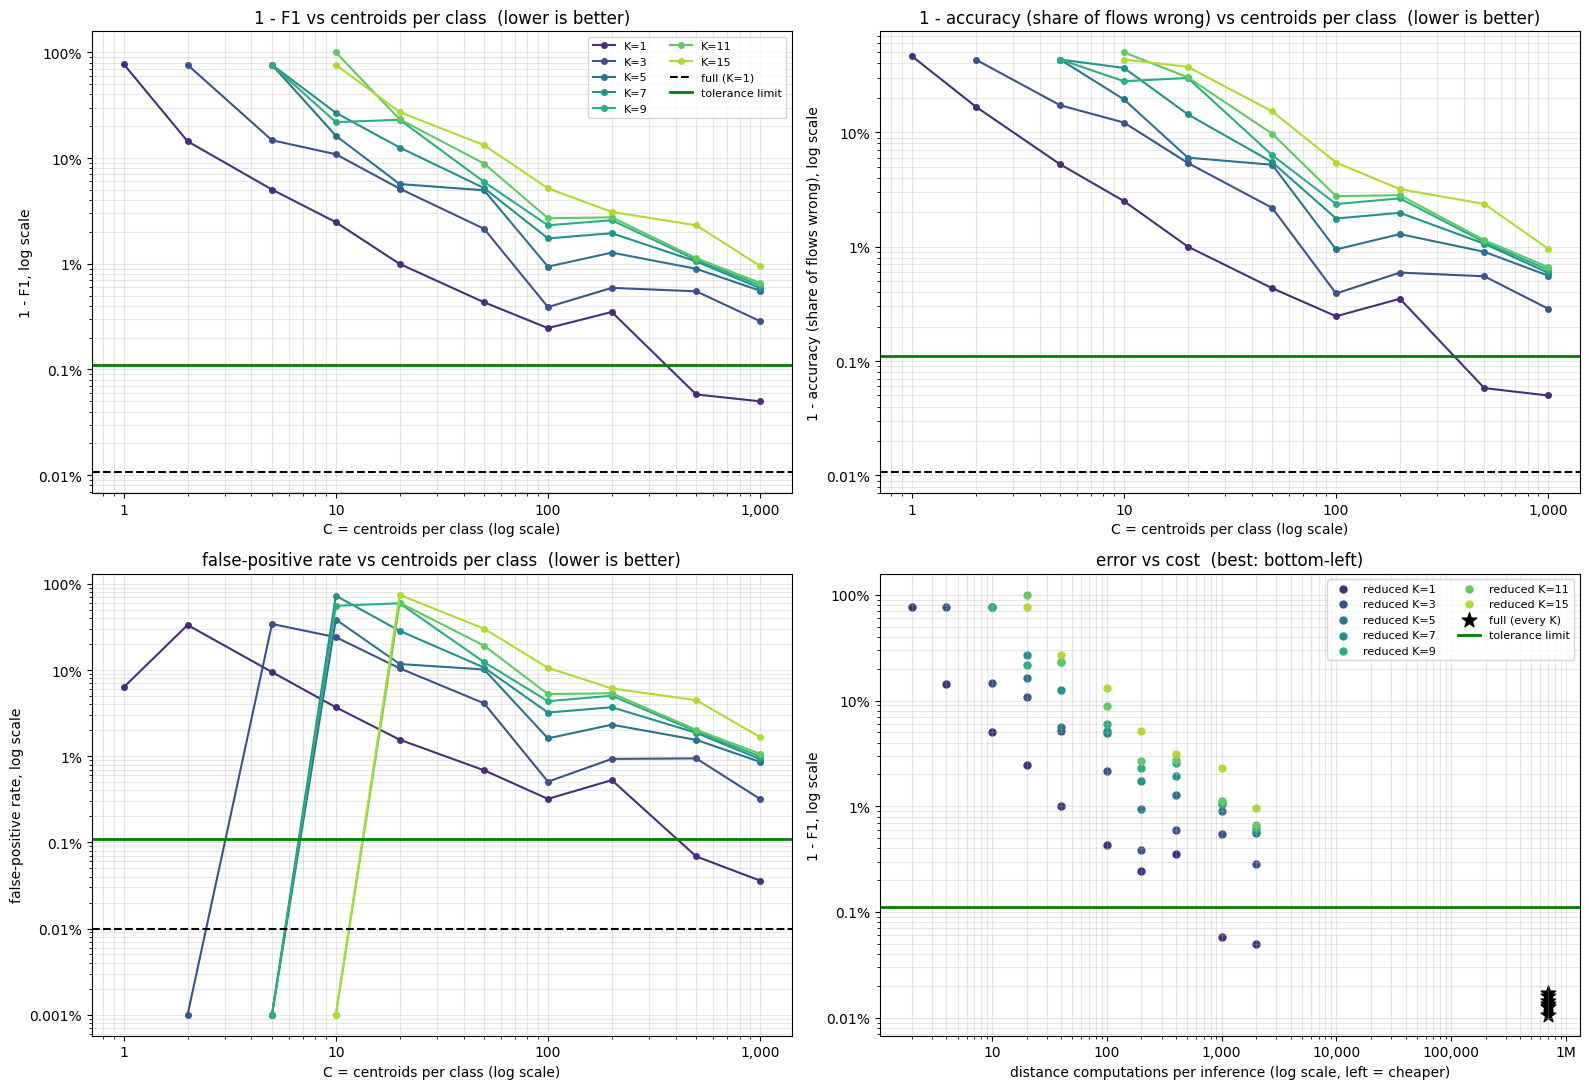

In [10]:
from matplotlib.ticker import FuncFormatter

for df in (full, reduced):
    df["f1_error"] = 1 - df["f1"]
    df["accuracy_error"] = 1 - df["accuracy"]
floor = lambda v: np.clip(v, 1e-5, None)                      # zero errors are drawn at 0.001% on the log axis
percent = FuncFormatter(lambda v, _: f"{100 * v:g}%")
plain = FuncFormatter(lambda v, _: f"{v / 1e6:g}M" if v >= 1e6 else f"{v:,.0f}" if v >= 1 else f"{v:g}")
palette = dict(zip(K_VALUES, sns.color_palette("viridis", len(K_VALUES))))
ref_values = {"f1_error": 1 - reference.f1, "accuracy_error": 1 - reference.accuracy, "fpr": reference.fpr}
limits = {"f1_error": ref_values["f1_error"] + MAX_F1_DROP,
          "accuracy_error": ref_values["accuracy_error"] + MAX_F1_DROP,   # same tolerance as F1, for reference
          "fpr": ref_values["fpr"] + MAX_FPR_INCREASE}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
panels = [(axes[0, 0], "f1_error", "1 - F1"), (axes[0, 1], "accuracy_error", "1 - accuracy (share of flows wrong)"),
          (axes[1, 0], "fpr", "false-positive rate")]
for ax, metric, ylabel in panels:
    for k in K_VALUES:
        s = reduced[reduced.k == k]
        ax.plot(s["C"], floor(s[metric]), marker="o", ms=4, color=palette[k], label=f"K={k}")
    ax.axhline(floor(ref_values[metric]), color="black", ls="--", label=f"full (K={int(reference.k)})")
    ax.axhline(limits[metric], color="green", lw=2, label="tolerance limit")
    ax.set(xscale="log", yscale="log", xlabel="C = centroids per class (log scale)",
           ylabel=f"{ylabel}, log scale", title=f"{ylabel} vs centroids per class  (lower is better)")
    ax.yaxis.set_major_formatter(percent)
    ax.xaxis.set_major_formatter(plain)
    ax.grid(alpha=0.3, which="both")
axes[0, 0].legend(fontsize=8, ncol=2)

ax = axes[1, 1]
for k in K_VALUES:
    s = reduced[reduced.k == k]
    ax.scatter(s["distance_computations"], floor(s["f1_error"]), color=palette[k], s=25, label=f"reduced K={k}")
ax.scatter(full["distance_computations"], floor(full["f1_error"]), color="black", marker="*", s=120,
           label="full (every K)")
ax.axhline(limits["f1_error"], color="green", lw=2, label="tolerance limit")
ax.set(xscale="log", yscale="log", xlabel="distance computations per inference (log scale, left = cheaper)",
       ylabel="1 - F1, log scale", title="error vs cost  (best: bottom-left)")
ax.yaxis.set_major_formatter(percent)
ax.xaxis.set_major_formatter(plain)
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "full_vs_reduced.png", dpi=150)
plt.show()

## 9. Choose the reduced model to deploy

**Rule for the best model.**

1. Keep only reduced models with the **same performance** as the full model (reference K):
   `F1 ≥ full F1 − MAX_F1_DROP` and `FPR ≤ full FPR + MAX_FPR_INCREASE`.
2. Among those, pick the **fewest distance computations** (smallest C), then the **fewest comparisons**
   (smallest K), then the highest F1.

If no reduced model meets the tolerance, the one with the highest F1 is reported instead (and flagged).

The cell after it compares **any** reduced model with the full model: set `COMPARE_MODEL` to `"best"` or to a
`(C, K)` pair, e.g. `(1000, 1)`.

In [11]:
ok = reduced[(reduced.f1 >= reference.f1 - MAX_F1_DROP) & (reduced.fpr <= reference.fpr + MAX_FPR_INCREASE)]
meets_tolerance = len(ok) > 0
pool = ok if meets_tolerance else reduced
best = pool.sort_values(["distance_computations", "comparisons", "f1"], ascending=[True, True, False]).iloc[0]
best_c, best_k = int(best.C), int(best.k)

print(f"Reduced models meeting the tolerance: {len(ok)} of {len(reduced)}")
if not meets_tolerance:
    print("WARNING: no reduced model meets the tolerance; showing the one with the highest F1 instead.")
print(f"Best reduced model (rule): C = {best_c} centroids per class ({2 * best_c} points), K = {best_k}")
with pd.option_context("display.float_format", "{:.5f}".format):
    display(ok.set_index(["C", "k"])[METRICS + ["distance_computations", "comparisons"]])

Reduced models meeting the tolerance: 2 of 57
Best reduced model (rule): C = 500 centroids per class (1000 points), K = 1


,,accuracy,precision,recall,f1,fpr,fnr,distance_computations,comparisons
C,k,,,,,,,,
500,1,0.99942,0.99931,0.99953,0.99942,0.00069,0.00047,1000,1000
1000,1,0.99950,0.99964,0.99936,0.99950,0.00036,0.00064,2000,2000


In [12]:
# ---- Choose the reduced model to compare with the full model ----
COMPARE_MODEL = "best"          # "best" (rule above) or a (C, K) pair from Section 7, e.g. (1000, 1)

cmp_c, cmp_k = (best_c, best_k) if COMPARE_MODEL == "best" else COMPARE_MODEL
assert (cmp_c, cmp_k) in reduced_models, f"(C={cmp_c}, K={cmp_k}) was not evaluated; valid: C in {C_VALUES}, K <= 2*C"
cmp_row = reduced[(reduced.C == cmp_c) & (reduced.k == cmp_k)].iloc[0]
cmp_ok = (cmp_row.f1 >= reference.f1 - MAX_F1_DROP) and (cmp_row.fpr <= reference.fpr + MAX_FPR_INCREASE)
cmp_name = f"reduced (C={cmp_c}, K={cmp_k})"

compare = pd.DataFrame({f"full (K={int(reference.k)})": reference, cmp_name: cmp_row}).T
compare = compare[METRICS + ["stored_points", "distance_computations", "arithmetic_ops", "comparisons"]].astype(float)
compare.loc["reduced / full"] = compare.iloc[1] / compare.iloc[0].replace(0, np.nan)
print(f"Comparing {cmp_name} with the full model  "
      f"({'meets' if cmp_ok else 'does NOT meet'} the same-performance tolerance)")
with pd.option_context("display.float_format", "{:.6g}".format):
    display(compare)
print(f"Distance computations per inference: {int(reference.distance_computations):,} -> "
      f"{int(cmp_row.distance_computations):,}  ({reference.distance_computations / cmp_row.distance_computations:,.0f}x fewer)")

Comparing reduced (C=500, K=1) with the full model  (meets the same-performance tolerance)


,accuracy,precision,recall,f1,fpr,fnr,stored_points,distance_computations,arithmetic_ops,comparisons
full (K=1),0.999893,0.9999,0.999887,0.999893,0.0001,0.000113333,700000,700000,5.6e+06,700000
"reduced (C=500, K=1)",0.99942,0.999313,0.999527,0.99942,0.000686667,0.000473333,1000,1000,8000,1000
reduced / full,0.999527,0.999413,0.99964,0.999527,6.86667,4.17647,0.00142857,0.00142857,0.00142857,0.00142857


Distance computations per inference: 700,000 -> 1,000  (700x fewer)


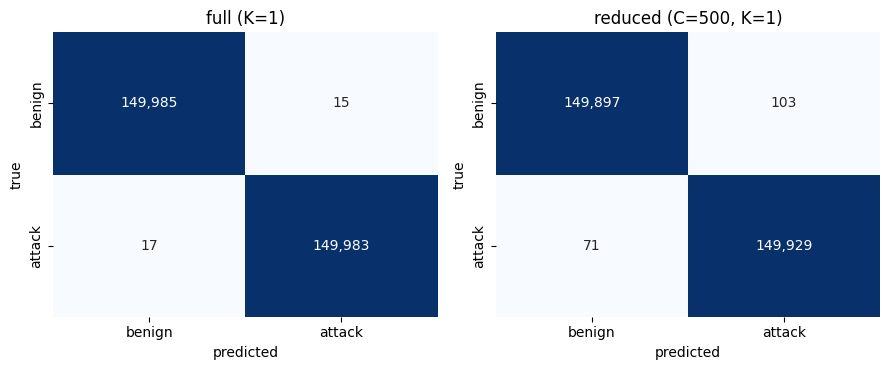

,test_rows,full,"reduced (C=500, K=1)"
attack_type,,,
Benign,150000,0.9999,0.9993
LDAP,79,1.0000,0.9494
MSSQL,60,0.9667,0.9000
NetBIOS,142,1.0000,0.9718
Portmap,22,0.9091,0.8182
Syn,129599,0.9999,0.9996
UDP,20075,1.0000,1.0000
UDPLag,23,1.0000,1.0000


In [13]:
# Confusion matrices and share of each traffic type classified correctly: full vs the model chosen above.
if "full_pred" not in globals():                               # computed once: 700,000 stored points, takes a while
    full_pred = joblib.load(FULL_BUNDLE_DIR / "model.joblib").predict(X_test)
cmp_pred = reduced_preds[(cmp_c, cmp_k)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (title, pred) in zip(axes, [(f"full (K={int(reference.k)})", full_pred),
                                    (cmp_name, cmp_pred)]):
    sns.heatmap(confusion_matrix(y_test, pred, labels=[0, 1]), annot=True, fmt=",d", cmap="Blues", cbar=False,
                ax=ax, xticklabels=list(CLASS_NAMES.values()), yticklabels=list(CLASS_NAMES.values()))
    ax.set(title=title, xlabel="predicted", ylabel="true")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_full_vs_reduced.png", dpi=150)
plt.show()

per_type = pd.DataFrame({
    "test_rows": test_df["attack_type"].value_counts(),
    "full": pd.Series(full_pred == y_test).groupby(test_df["attack_type"]).mean(),
    cmp_name: pd.Series(cmp_pred == y_test).groupby(test_df["attack_type"]).mean(),
})
per_type.to_csv(RESULTS_DIR / "correct_rate_per_type_full_vs_reduced.csv")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(per_type)

C20 k1 n5

In [14]:
# ---- Choose the reduced model to compare with the full model ----
COMPARE_MODEL = (20, 1)          # "best" (rule above) or a (C, K) pair from Section 7, e.g. (1000, 1)

cmp_c, cmp_k = (best_c, best_k) if COMPARE_MODEL == "best" else COMPARE_MODEL
assert (cmp_c, cmp_k) in reduced_models, f"(C={cmp_c}, K={cmp_k}) was not evaluated; valid: C in {C_VALUES}, K <= 2*C"
cmp_row = reduced[(reduced.C == cmp_c) & (reduced.k == cmp_k)].iloc[0]
cmp_ok = (cmp_row.f1 >= reference.f1 - MAX_F1_DROP) and (cmp_row.fpr <= reference.fpr + MAX_FPR_INCREASE)
cmp_name = f"reduced (C={cmp_c}, K={cmp_k})"

compare = pd.DataFrame({f"full (K={int(reference.k)})": reference, cmp_name: cmp_row}).T
compare = compare[METRICS + ["stored_points", "distance_computations", "arithmetic_ops", "comparisons"]].astype(float)
compare.loc["reduced / full"] = compare.iloc[1] / compare.iloc[0].replace(0, np.nan)
print(f"Comparing {cmp_name} with the full model  "
      f"({'meets' if cmp_ok else 'does NOT meet'} the same-performance tolerance)")
with pd.option_context("display.float_format", "{:.6g}".format):
    display(compare)
print(f"Distance computations per inference: {int(reference.distance_computations):,} -> "
      f"{int(cmp_row.distance_computations):,}  ({reference.distance_computations / cmp_row.distance_computations:,.0f}x fewer)")

Comparing reduced (C=20, K=1) with the full model  (does NOT meet the same-performance tolerance)


,accuracy,precision,recall,f1,fpr,fnr,stored_points,distance_computations,arithmetic_ops,comparisons
full (K=1),0.999893,0.9999,0.999887,0.999893,0.0001,0.000113333,700000,700000,5.6e+06,700000
"reduced (C=20, K=1)",0.989987,0.984636,0.995507,0.990042,0.0155333,0.00449333,40,40,320,40
reduced / full,0.990092,0.984735,0.99562,0.990147,155.333,39.6471,5.71429e-05,5.71429e-05,5.71429e-05,5.71429e-05


Distance computations per inference: 700,000 -> 40  (17,500x fewer)


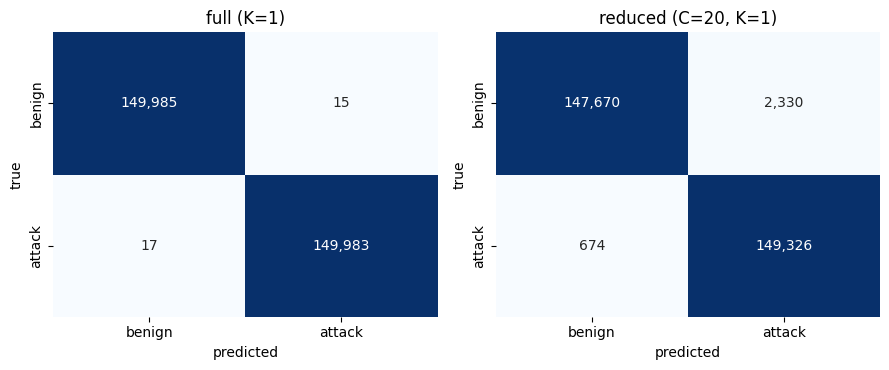

,test_rows,full,"reduced (C=20, K=1)"
attack_type,,,
Benign,150000,0.9999,0.9845
LDAP,79,1.0000,0.9241
MSSQL,60,0.9667,0.4833
NetBIOS,142,1.0000,0.9225
Portmap,22,0.9091,0.2727
Syn,129599,0.9999,0.9954
UDP,20075,1.0000,0.9999
UDPLag,23,1.0000,0.5217


In [15]:
# Confusion matrices and share of each traffic type classified correctly: full vs the model chosen above.
if "full_pred" not in globals():                               # computed once: 700,000 stored points, takes a while
    full_pred = joblib.load(FULL_BUNDLE_DIR / "model.joblib").predict(X_test)
cmp_pred = reduced_preds[(cmp_c, cmp_k)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (title, pred) in zip(axes, [(f"full (K={int(reference.k)})", full_pred),
                                    (cmp_name, cmp_pred)]):
    sns.heatmap(confusion_matrix(y_test, pred, labels=[0, 1]), annot=True, fmt=",d", cmap="Blues", cbar=False,
                ax=ax, xticklabels=list(CLASS_NAMES.values()), yticklabels=list(CLASS_NAMES.values()))
    ax.set(title=title, xlabel="predicted", ylabel="true")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_full_vs_reduced.png", dpi=150)
plt.show()

per_type = pd.DataFrame({
    "test_rows": test_df["attack_type"].value_counts(),
    "full": pd.Series(full_pred == y_test).groupby(test_df["attack_type"]).mean(),
    cmp_name: pd.Series(cmp_pred == y_test).groupby(test_df["attack_type"]).mean(),
})
per_type.to_csv(RESULTS_DIR / "correct_rate_per_type_full_vs_reduced.csv")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(per_type)

## 10. Save a reduced model

Set `SAVE_MODEL` to `"best"` (the rule in Section 9) or to a `(C, K)` pair to save a custom choice. Each saved model gets its own folder, `models/knn_n5_raw_reduced/knn_n5_raw_c<C>_k<K>/`, so several can be kept side by side:

| File | Contents |
|---|---|
| `centroids.csv` | the 2·C labeled centroids (`total_bytes, packet_length_max, iat_max, label`): **this is what the hardware stores** |
| `model.joblib` | `KNeighborsClassifier` fitted on the centroids |
| `metadata.json` | features in input order, units, flow definition, C, K, cost per inference, test metrics, comparison with the full model, versions |
| `results_full_vs_reduced.csv` | metrics and cost of every full and reduced model |

All centroid sets (every C) are also kept in `models/knn_n5_raw_reduced/centroids/`.

In [16]:
# ---- Choose the reduced model to save ----
SAVE_MODEL = "best"             # "best" (rule in Section 9) or a (C, K) pair from Section 7, e.g. (1000, 1)

save_c, save_k = (best_c, best_k) if SAVE_MODEL == "best" else SAVE_MODEL
assert (save_c, save_k) in reduced_models, f"(C={save_c}, K={save_k}) was not evaluated"
saved = reduced[(reduced.C == save_c) & (reduced.k == save_k)].iloc[0]
save_ok = (saved.f1 >= reference.f1 - MAX_F1_DROP) and (saved.fpr <= reference.fpr + MAX_FPR_INCREASE)
print(f"Saving reduced model C = {save_c}, K = {save_k} "
      f"({'best by rule' if (save_c, save_k) == (best_c, best_k) else 'custom choice'}; "
      f"{'meets' if save_ok else 'does NOT meet'} the same-performance tolerance)")

BUNDLE_DIR = MODELS_DIR / f"knn_n{N}_raw_c{save_c}_k{save_k}"
BUNDLE_DIR.mkdir(parents=True, exist_ok=True)

centroid_sets[save_c].to_csv(BUNDLE_DIR / "centroids.csv", index=False)
joblib.dump(reduced_models[(save_c, save_k)], BUNDLE_DIR / "model.joblib")
all_results.to_csv(BUNDLE_DIR / "results_full_vs_reduced.csv", index=False)

metadata = {
    **{key: full_meta[key] for key in ["features", "feature_units", "scaling", "labels", "flow", "known_limitation"]},
    "model": "sklearn.neighbors.KNeighborsClassifier on per-class k-means centroids",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "k": save_k,
    "centroids_per_class": save_c,
    "stored_points": 2 * save_c,
    "weights": "uniform",
    "metric": "euclidean (squared distance is enough: no sqrt)",
    "decision": "attack if more than half of the k nearest centroids are attack centroids",
    "cost_per_inference": {key: int(saved[key]) for key in
                           ["stored_points", "stored_values", "distance_computations", "arithmetic_ops", "comparisons"]},
    "test_metrics": {m: float(saved[m]) for m in METRICS},
    "full_model": {"bundle": str(FULL_BUNDLE_DIR), "k": int(reference.k),
                   "stored_points": int(reference.stored_points),
                   "test_metrics": {m: float(reference[m]) for m in METRICS}},
    "reduction": {
        "method": "MiniBatchKMeans per class on raw training features",
        "c_values_compared": C_VALUES, "k_values_compared": K_VALUES,
        "tolerance": {"max_f1_drop": MAX_F1_DROP, "max_fpr_increase": MAX_FPR_INCREASE},
        "meets_tolerance": bool(save_ok),
        "selected_by": "rule" if (save_c, save_k) == (best_c, best_k) else "manual choice",
        "best_by_rule": {"C": best_c, "k": best_k},
        "selection_rule": "same performance as full model within tolerance, then fewest distance computations, "
                          "then fewest comparisons, then highest F1",
        "random_state": RANDOM_STATE,
    },
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(BUNDLE_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

print(f"Saved reduced model bundle: {BUNDLE_DIR}")
for f in sorted(BUNDLE_DIR.iterdir()):
    print(f"  {f.name:<28} {f.stat().st_size / 1e3:10.1f} KB")

Saving reduced model C = 500, K = 1 (best by rule; meets the same-performance tolerance)
Saved reduced model bundle: /home/ubuntu/DDoS_ML/offline/models/knn_n5_raw_reduced/knn_n5_raw_c500_k1
  centroids.csv                      48.6 KB
  metadata.json                       3.0 KB
  model.joblib                       70.5 KB
  results_full_vs_reduced.csv        10.3 KB


In [17]:
# ---- Choose the reduced model to save ----
SAVE_MODEL = (20,1)            # "best" (rule in Section 9) or a (C, K) pair from Section 7, e.g. (1000, 1)

save_c, save_k = (best_c, best_k) if SAVE_MODEL == "best" else SAVE_MODEL
assert (save_c, save_k) in reduced_models, f"(C={save_c}, K={save_k}) was not evaluated"
saved = reduced[(reduced.C == save_c) & (reduced.k == save_k)].iloc[0]
save_ok = (saved.f1 >= reference.f1 - MAX_F1_DROP) and (saved.fpr <= reference.fpr + MAX_FPR_INCREASE)
print(f"Saving reduced model C = {save_c}, K = {save_k} "
      f"({'best by rule' if (save_c, save_k) == (best_c, best_k) else 'custom choice'}; "
      f"{'meets' if save_ok else 'does NOT meet'} the same-performance tolerance)")

BUNDLE_DIR = MODELS_DIR / f"knn_n{N}_raw_c{save_c}_k{save_k}"
BUNDLE_DIR.mkdir(parents=True, exist_ok=True)

centroid_sets[save_c].to_csv(BUNDLE_DIR / "centroids.csv", index=False)
joblib.dump(reduced_models[(save_c, save_k)], BUNDLE_DIR / "model.joblib")
all_results.to_csv(BUNDLE_DIR / "results_full_vs_reduced.csv", index=False)

metadata = {
    **{key: full_meta[key] for key in ["features", "feature_units", "scaling", "labels", "flow", "known_limitation"]},
    "model": "sklearn.neighbors.KNeighborsClassifier on per-class k-means centroids",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "k": save_k,
    "centroids_per_class": save_c,
    "stored_points": 2 * save_c,
    "weights": "uniform",
    "metric": "euclidean (squared distance is enough: no sqrt)",
    "decision": "attack if more than half of the k nearest centroids are attack centroids",
    "cost_per_inference": {key: int(saved[key]) for key in
                           ["stored_points", "stored_values", "distance_computations", "arithmetic_ops", "comparisons"]},
    "test_metrics": {m: float(saved[m]) for m in METRICS},
    "full_model": {"bundle": str(FULL_BUNDLE_DIR), "k": int(reference.k),
                   "stored_points": int(reference.stored_points),
                   "test_metrics": {m: float(reference[m]) for m in METRICS}},
    "reduction": {
        "method": "MiniBatchKMeans per class on raw training features",
        "c_values_compared": C_VALUES, "k_values_compared": K_VALUES,
        "tolerance": {"max_f1_drop": MAX_F1_DROP, "max_fpr_increase": MAX_FPR_INCREASE},
        "meets_tolerance": bool(save_ok),
        "selected_by": "rule" if (save_c, save_k) == (best_c, best_k) else "manual choice",
        "best_by_rule": {"C": best_c, "k": best_k},
        "selection_rule": "same performance as full model within tolerance, then fewest distance computations, "
                          "then fewest comparisons, then highest F1",
        "random_state": RANDOM_STATE,
    },
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(BUNDLE_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

print(f"Saved reduced model bundle: {BUNDLE_DIR}")
for f in sorted(BUNDLE_DIR.iterdir()):
    print(f"  {f.name:<28} {f.stat().st_size / 1e3:10.1f} KB")

Saving reduced model C = 20, K = 1 (custom choice; does NOT meet the same-performance tolerance)
Saved reduced model bundle: /home/ubuntu/DDoS_ML/offline/models/knn_n5_raw_reduced/knn_n5_raw_c20_k1
  centroids.csv                       2.2 KB
  metadata.json                       3.0 KB
  model.joblib                        4.1 KB
  results_full_vs_reduced.csv        10.3 KB


## 11. Check that the saved model reloads

Load the bundle as another notebook would, check it reproduces the predictions above, and check that a KNN rebuilt
from `centroids.csv` alone (what the hardware stores) gives the same predictions.

In [23]:
loaded_meta = json.loads((BUNDLE_DIR / "metadata.json").read_text())
loaded_model = joblib.load(BUNDLE_DIR / "model.joblib")
cents = pd.read_csv(BUNDLE_DIR / "centroids.csv")
rebuilt = KNeighborsClassifier(n_neighbors=loaded_meta["k"]).fit(cents[loaded_meta["features"]].to_numpy(),
                                                                 cents["label"].to_numpy())
X_check = test_df[loaded_meta["features"]].to_numpy()

checks = {
    "metadata features == FEATURES": loaded_meta["features"] == FEATURES,
    f"centroids.csv has 2*C = {2 * save_c} rows": len(cents) == 2 * save_c,
    "reloaded model: same predictions on the test split":
        bool((loaded_model.predict(X_check) == reduced_preds[(save_c, save_k)]).all()),
    "rebuilt from centroids.csv: same predictions":
        bool((rebuilt.predict(X_check) == reduced_preds[(save_c, save_k)]).all()),
}
for name, passed in checks.items():
    print(f"[{'OK' if passed else 'FAIL'}] {name}")
assert all(checks.values())

[OK] metadata features == FEATURES
[OK] centroids.csv has 2*C = 1000 rows
[OK] reloaded model: same predictions on the test split
[OK] rebuilt from centroids.csv: same predictions


### Using the reduced model in another notebook

```python
import json, joblib
import pandas as pd
from pathlib import Path

BUNDLE_DIR = Path("/home/ubuntu/DDoS_ML/offline/models/knn_n5_raw_reduced/knn_n5_raw_c<C>_k<K>")   # from Section 10
meta  = json.loads((BUNDLE_DIR / "metadata.json").read_text())
model = joblib.load(BUNDLE_DIR / "model.joblib")
# Or rebuild it from the centroids (no joblib / version issues):
#   from sklearn.neighbors import KNeighborsClassifier
#   c = pd.read_csv(BUNDLE_DIR / "centroids.csv")
#   model = KNeighborsClassifier(n_neighbors=meta["k"]).fit(c[meta["features"]].to_numpy(), c["label"])

new_flows = pd.read_csv("unseen_flows.csv")                 # one row per flow, features as in metadata["flow"]
new_flows["pred"] = model.predict(new_flows[meta["features"]].to_numpy())   # 1 = attack, 0 = benign
```

### Inference in hardware

Load the `2·C` rows of `centroids.csv` into the device once. For each flow, after its 5th packet:

```
best = K empty slots (distance = +infinity)
for each centroid (x1, x2, x3, label):                       # 2*C iterations
    d = (total_bytes - x1)^2 + (packet_length_max - x2)^2 + (iat_max - x3)^2
    if d < largest distance in best: replace it with (d, label)
predict attack if more than K/2 of the labels in best are 1
```
For K = 1 this is a running minimum: keep `(min_d, label)` and output that label.

### Conclusion

* **Best reduced model:** printed in Section 9 (C centroids per class, K neighbors). Any other (C, K) can be compared
  with the full model (`COMPARE_MODEL`) and saved instead (`SAVE_MODEL`).
* **Why it is safe to use:** it is the cheapest model whose test F1 and FPR stay within `MAX_F1_DROP` /
  `MAX_FPR_INCREASE` of the full model on the same test flows. Check the per-traffic-type table in Section 9 for any
  type that the reduced model handles much worse than the full model.
* **Cost in hardware:** `2·C` stored points (`3·2·C` values), `2·C` squared distances and at most `2·C·K`
  comparisons per inference, against 700,000 distances for the full model.
* **Same caveat as the full model:** the benign training data is capped at 96 bytes per packet (MAWI snaplen), so
  test scores are not expected to hold on live traffic until the benign data is re-extracted with the IP total length.
  Re-run `training_binary_knn_n5_k1.ipynb` and then this notebook after re-extraction.